## Climate Model and Climate Data Workshop - Hands-on Session
### Climate CH2025 example

This Jupyter notebook showcases how to download and use CH2025 data in Python. However, it is not a Python course!

https://www.meteoschweiz.admin.ch/klima/klimawandel/schweizer-klimaszenarien/berichte-daten-und-grafiken-der-klimaszenarien/klima-ch2025-datensaetze.html

https://opendatadocs.meteoswiss.ch/c-climate-data/c8-c9-climate-scenarios

In [1]:
import xarray as xr
import glob
#from pathlib import Path

In [2]:
variable = "pr" #precipitation
ref = "ref91-20"
gwl = "gwl3.0"

In [3]:
path_ch2025 = f"/net/dust/c2sm-data/rlorenz/climate_model_data_workshop/ogd-climate-scenarios-ch2025-grid/{variable}"

In [4]:
#ref_data = f"{path_ch2025}/ogd-climate-scenarios-ch2025-grid_ch_{variable}_*_{ref}.nc"
gwl_data = f"ogd-climate-scenarios-ch2025-grid_ch_{variable}_*_{gwl}.nc"

1. Calculate the difference between the reference period and GWL3.0 for each model
2. Calulate the multi-model median, smallest and largest difference
3. Plot the median, smallest and largest difference

In [11]:
diff_all_models_list = list()
for file in glob.glob(f"{path_ch2025}/{gwl_data}"):
    model_name = file.split("_")[6]
    print(model_name)
    ds_gwl = xr.open_dataset(file)
    # find matching ref data
    ds_ref = xr.open_dataset(f"{path_ch2025}/ogd-climate-scenarios-ch2025-grid_ch_{variable}_{model_name}_{ref}.nc")

    ds_diff = ds_gwl.mean(dim="time") - ds_ref.mean(dim="time")
    #print(ds_diff)
    diff_all_models_list.append(ds_diff)

clmcom-cclm4-cccma
<xarray.Dataset> Size: 1MB
Dimensions:                 (N: 240, E: 370)
Coordinates:
  * N                       (N) float64 2kB 1.064e+06 1.066e+06 ... 1.304e+06
  * E                       (E) float64 3kB 2.474e+06 2.476e+06 ... 2.844e+06
    lon                     (N, E) float32 355kB 5.827 5.84 ... 10.68 10.69
    lat                     (N, E) float32 355kB 45.72 45.72 ... 47.84 47.84
Data variables:
    swiss_lv95_coordinates  float64 8B 0.0
    pr                      (N, E) float32 355kB nan nan nan nan ... nan nan nan
clmcom-cclm4-ecearth
<xarray.Dataset> Size: 1MB
Dimensions:                 (N: 240, E: 370)
Coordinates:
  * N                       (N) float64 2kB 1.064e+06 1.066e+06 ... 1.304e+06
  * E                       (E) float64 3kB 2.474e+06 2.476e+06 ... 2.844e+06
    lon                     (N, E) float32 355kB 5.827 5.84 ... 10.68 10.69
    lat                     (N, E) float32 355kB 45.72 45.72 ... 47.84 47.84
Data variables:
    swiss_lv95_c

NameError: name 'ds_diff_all_models' is not defined

In [15]:
ds_diff_all_models = xr.concat(diff_all_models_list, dim="model")

In [16]:
ds_diff_all_models

<xarray.Dataset> Size: 9MB
Dimensions:                 (model: 24, N: 240, E: 370)
Coordinates:
  * N                       (N) float64 2kB 1.064e+06 1.066e+06 ... 1.304e+06
  * E                       (E) float64 3kB 2.474e+06 2.476e+06 ... 2.844e+06
    lon                     (N, E) float32 355kB 5.827 5.84 ... 10.68 10.69
    lat                     (N, E) float32 355kB 45.72 45.72 ... 47.84 47.84
Dimensions without coordinates: model
Data variables:
    swiss_lv95_coordinates  (model) float64 192B 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    pr                      (model, N, E) float32 9MB nan nan nan ... nan nan

In [17]:
model_median = ds_diff_all_models.median(dim="model")

In [18]:
model_median

<xarray.Dataset> Size: 1MB
Dimensions:                 (N: 240, E: 370)
Coordinates:
  * N                       (N) float64 2kB 1.064e+06 1.066e+06 ... 1.304e+06
  * E                       (E) float64 3kB 2.474e+06 2.476e+06 ... 2.844e+06
    lon                     (N, E) float32 355kB 5.827 5.84 ... 10.68 10.69
    lat                     (N, E) float32 355kB 45.72 45.72 ... 47.84 47.84
Data variables:
    swiss_lv95_coordinates  float64 8B 0.0
    pr                      (N, E) float64 710kB nan nan nan nan ... nan nan nan

In [19]:
model_min = ds_diff_all_models.min(dim="model")
model_max = ds_diff_all_models.max(dim="model")

In [20]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

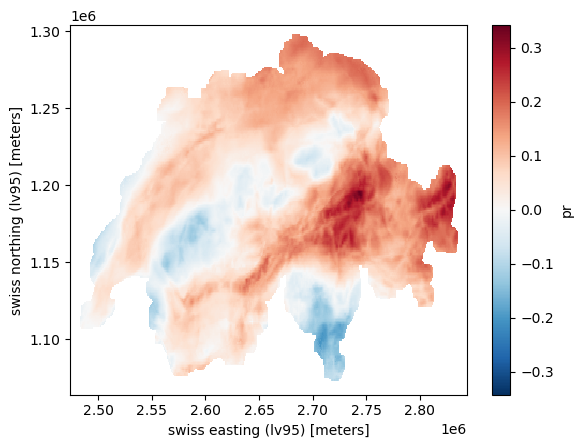

In [22]:
model_median["pr"].plot()

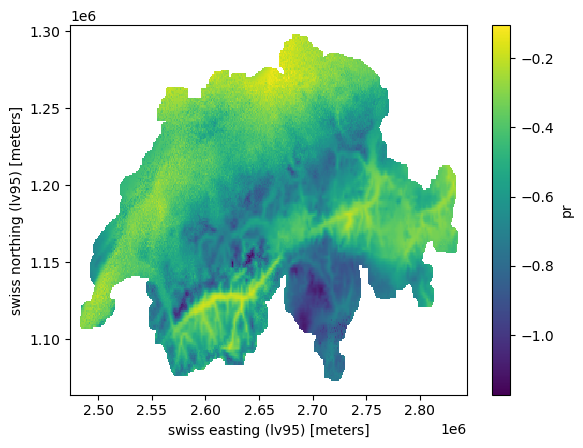

In [23]:
model_min["pr"].plot()

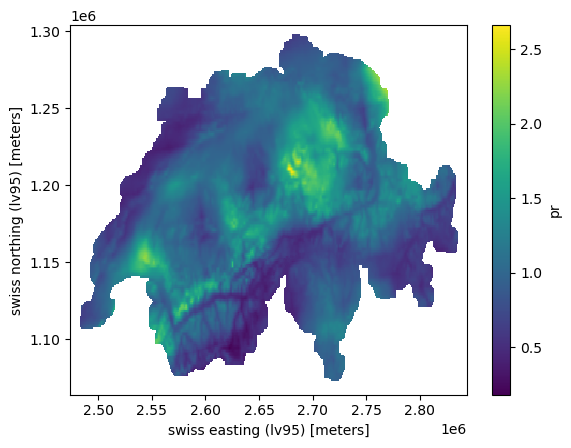

In [24]:
model_max["pr"].plot()